# Importing Required Libraries

In [32]:
import pandas as pd
import numpy as np
import sys
import warnings
import itertools
warnings.filterwarnings("ignore")
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
from pandas.plotting import lag_plot
import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
%matplotlib inline
import datetime
import calendar
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima_model import ARMA
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

Importing the Dataset

In [33]:
data = pd.read_csv('/content/datasets_56102_107707_monthly-beer-production-in-austr.csv')
data.head()

,Month,Monthly beer production
0,1956-01,93.2
1,1956-02,96.0
2,1956-03,95.2
3,1956-04,77.1
4,1956-05,70.9


Creating a date range

In [34]:
dates = pd.date_range(start='1964-01-01', freq='MS', periods=len(data))
dates[0:5]

DatetimeIndex(['1964-01-01', '1964-02-01', '1964-03-01', '1964-04-01',
               '1964-05-01'],
              dtype='datetime64[ns]', freq='MS')

In [35]:
data.set_index(dates,inplace=True)
data.drop('Month',axis=1,inplace=True)

# Modeling

In [36]:
train = (data[data.index < '1969-10-01'])
test = (data[data.index >= '1969-10-01'])

# Model 1: Auto Regressive

Auto regression model creates a lag data so that correlation of the created lag is high with the original data.
No.of lag can be defined manually  by seeing ACF plot. By default the algorithm shows the best lag.

In [37]:
lags=12
model = AutoReg(train,lags=lags)
model_fit = model.fit()

In [38]:
# Assuming you have already fitted the model (as shown in the previous code snippet)

# Get the number of lags considered statistically
lags_statistically = lags

# Get the coefficients (beta values) of the model
coefficients = model_fit.params

# Print the results
print(f"Lags considered statistically: {lags_statistically}")
print(f"Coefficients (beta values):\n{coefficients}")

Lags considered statistically: 12
Coefficients (beta values):
const                          15.550603
Monthly beer production.L1      0.102827
Monthly beer production.L2      0.044350
Monthly beer production.L3     -0.006619
Monthly beer production.L4     -0.117912
Monthly beer production.L5      0.141437
Monthly beer production.L6     -0.084764
Monthly beer production.L7     -0.090432
Monthly beer production.L8      0.042982
Monthly beer production.L9      0.069728
Monthly beer production.L10    -0.120060
Monthly beer production.L11     0.225705
Monthly beer production.L12     0.626669
dtype: float64


The no of best lag for this data is 11 and all the correlation of the lags with the original sales is listed

In [39]:
# Predicting the test values
predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

In [40]:
print('The first test value in Sales :',test.values[1],'and its Predicted value : ',predictions.values[1])

The first test value in Sales : [116.3] and its Predicted value :  106.4981265844107


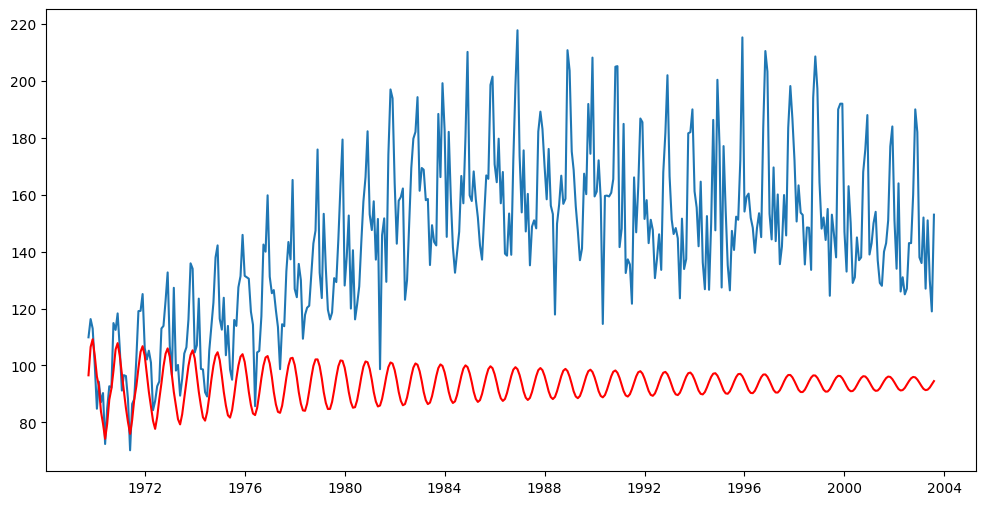

In [41]:
# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

In [42]:
# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['Monthly beer production'], predictions))
rmse = round(rmse, 3)

In [43]:
# Mean Absolute Percentage Error
abs_error = np.abs(test['Monthly beer production']-predictions)
actual = test['Monthly beer production']
mape = np.round(np.mean(abs_error/actual),3)
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'RMSE': [rmse]})
resultsDf
mape

np.float64(0.331)

In [44]:
# Storing results in a dataframe
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'MAPE': [mape], 'RMSE': [rmse]})
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive,57.926,0.331


# Model 2: Auto Regressive Integrated Moving Average(ARIMA)

The model involves specifying the order for the AR(p) and MA(q) model

Best ARIMA (6, 0) model - AIC:479.8372720606309
Order of AR part: 6
Coefficients: const     88.171199
ar.L1      0.469363
ar.L2      0.001377
ar.L3     -0.034076
ar.L4     -0.225754
ar.L5      0.002557
ar.L6     -0.371176
sigma2    46.704491
dtype: float64


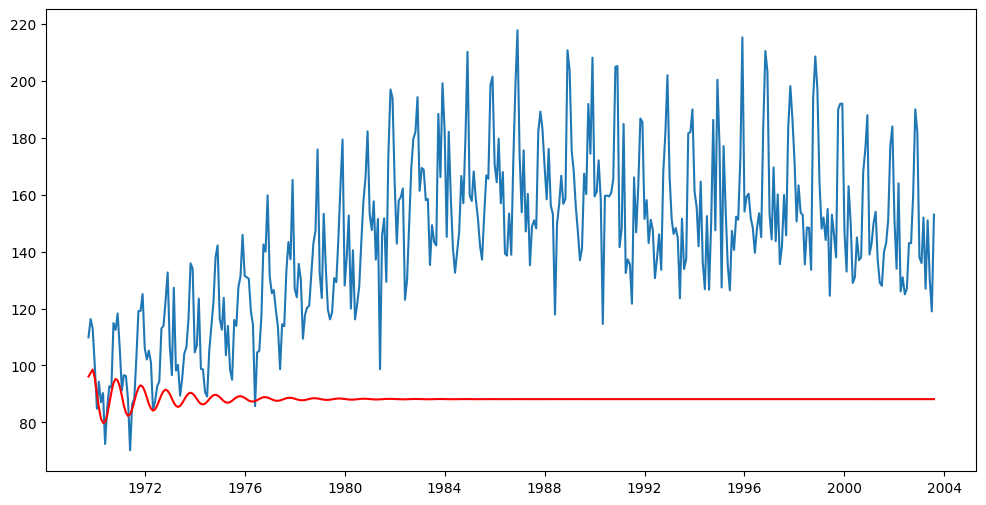

,Method,RMSE,MAPE
0,Auto Regressive,57.926,0.331
0,Auto Regressive Moving average,63.320,0.365


In [45]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Define the p and q parameters to take any value between 0 and 7
p = range(0, 7)
q = range(0,1)

# Generate all different combinations of p,q
pq = list(itertools.product(p,q))

best_aic = np.inf
best_pq = None
temp_model = None

for param in pq:
    try:
        temp_model = ARIMA(train, order=(param[0], 0, param[1]))
        results = temp_model.fit()
        if results.aic < best_aic:
            best_aic = results.aic
            best_pq = param
    except:
        continue

print("Best ARIMA {} model - AIC:{}".format(best_pq, best_aic))

# using the best parameter in the model
model = ARIMA(train, order=(best_pq[0], 0, best_pq[1]))
model_fit = model.fit()

# Print the order of the AR part of the model
print('Order of AR part: %s' % best_pq[0])

# Print the coefficients
print('Coefficients: %s' % model_fit.params)

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['Monthly beer production'], predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test['Monthly beer production']-predictions)
actual = test['Monthly beer production']
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Auto Regressive Moving average '], 'RMSE': [rmse],'MAPE': [mape] })
resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

# Model 2: Seasonal Auto Regressive Integrated Moving Average(SARIMA)

It combines the ARIMA model with the ability to perform the same autoregression, differencing, and moving average modeling at the seasonal level.

Best SARIMA (0, 1, 1) x (0, 1, 1, 12) model - AIC:253.993556052316


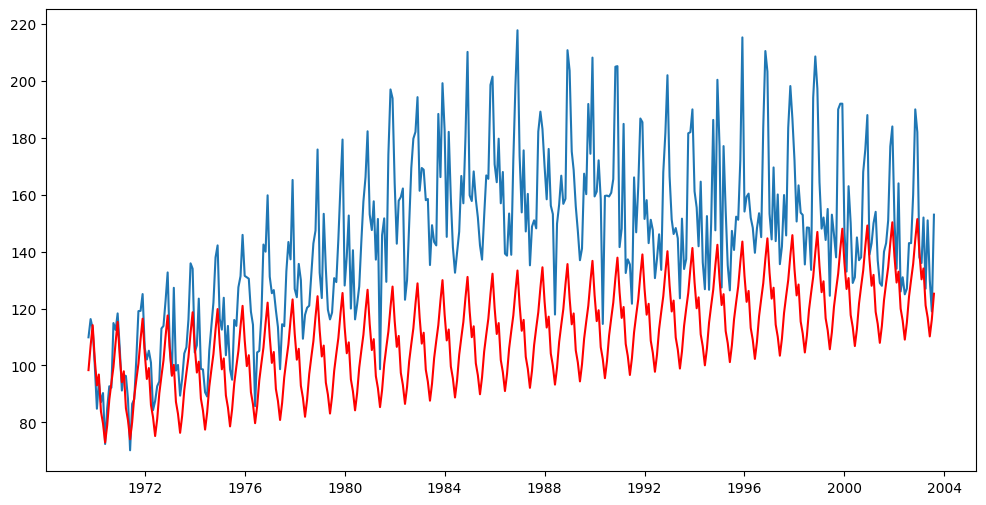

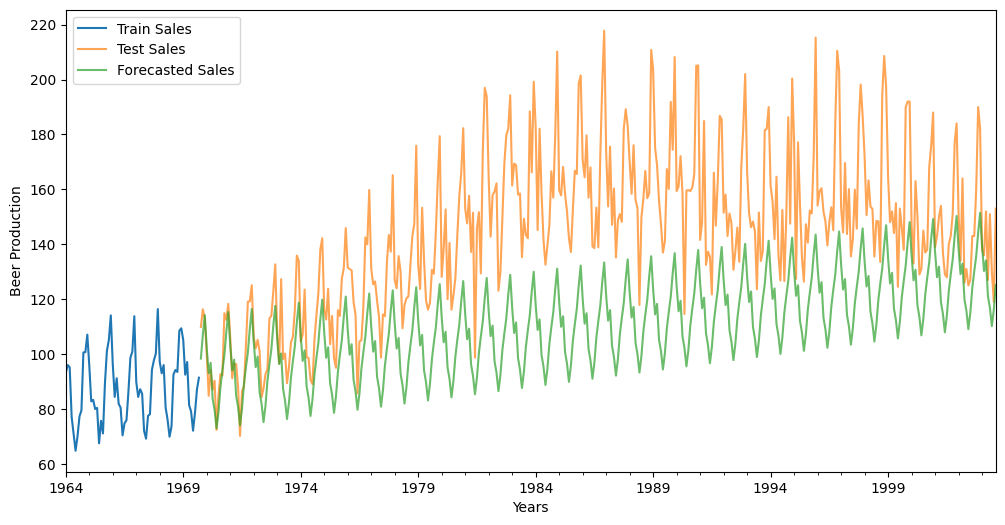

In [30]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Define the p, d and q parameters to take any value between 0 and 2
p = d = q = range(0, 2)

# Generate all different combinations of p, d and q triplets
pdq = list(itertools.product(p, d, q))

# Generate all different combinations of seasonal p, q and q triplets
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, d, q))]

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            temp_model = SARIMAX(train, order=param, seasonal_order=param_seasonal, enforce_invertibility=False, enforce_stationarity=False)
            results = temp_model.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal
        except:
            continue

print("Best SARIMA {} x {} model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))

# using the best parameter in the model
model = SARIMAX(train, order=best_pdq, seasonal_order=best_seasonal_pdq, enforce_invertibility=False, enforce_stationarity=False)
model_fit = model.fit()

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['Monthly beer production'], predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test['Monthly beer production']-predictions)
actual = test['Monthly beer production']
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Seasonal Autoregressive Integrated Moving Average'], 'RMSE': [rmse],'MAPE': [mape] })
resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf.index = [i for i in range(len(resultsDf))]
resultsDf

# Plotting the train, test and forecasted sales
axis = train['Monthly beer production'].plot(label='Train Sales', figsize=(12, 6))
test['Monthly beer production'].plot(ax=axis, label='Test Sales', alpha=0.7)
predictions.plot(ax=axis, label='Forecasted Sales', alpha=0.7)
axis.set_xlabel('Years')
axis.set_ylabel('Beer Production')
plt.legend(loc='best')
plt.show()
plt.close()

In [31]:
# Storing results in a dataframe

print(resultsDf)

                                              Method    RMSE   MAPE
0                                    Auto Regressive  57.926  0.331
1                    Auto Regressive Moving average   63.320  0.365
2  Seasonal Autoregressive Integrated Moving Average  38.842  0.220
